# Predicting Retail Food Prices in Rwandan Markets

**Mission:** My mission is to use technology to solve Africa's agricultural challenges by developing practical digital solutions that increase productivity, improve market access, create employment opportunities for youth, and strengthen food security for future generations.

## Use case
Farmers, small traders and food-security organisations in Rwanda need to know what a crop will sell for **before** they take it to market. This model predicts the **retail price (RWF per kg)** of a food commodity in a specific market, district and month.

- **Farmers** can decide *when* and *where* to sell their harvest.
- **Traders** can plan what to buy and where to resell it.
- **NGOs and cooperatives** can spot markets where food is becoming too expensive.

## Dataset
- **Name:** Rwanda – Food Prices (World Food Programme)
- **Source:** Humanitarian Data Exchange (HDX): https://data.humdata.org/dataset/wfp-food-prices-for-rwanda
- **Collected by:** WFP, MINAGRI and FAO (GIEWS/FPMA), updated every month.
- **Size:** about 158,000 rows and 16 columns (2000–2026), covering 109 markets in all 5 provinces and 65 commodities.
- **Variety:** numeric columns (latitude, longitude, price) and categorical columns (province, district, market, commodity, category, unit, price type, price flag), plus a date column.
- **Target:** `price`, the price in Rwandan francs (a continuous number, so this is a regression problem).

## Scope: what this model predicts
The model predicts prices for **foods sold per kilogram only** (54 commodities, such as maize, beans, Irish potatoes, rice, cassava flour, tomatoes, beef, goat meat and fish). The dataset also has products sold in other units, which are **out of scope**:

| Unit in the data | Products | Why they are out of scope |
|---|---|---|
| `Unit` (per animal or piece) | Live goats, sheep, cattle, pigs and hens, eggs, avocados | Priced per animal or per piece |
| `L` (per litre) | Milk, cooking oil, palm oil | Priced per litre |
| `Sack` | Charcoal | Not a food, and the dataset doesn't say how many kg a sack holds |

Keeping one unit means the predicted number always means the same thing: **RWF per kg**. Note that some foods appear in two forms: "Meat (goat)" is goat meat sold **per kg** (in scope), while "Livestock (Goat)" is a **live animal** sold whole (out of scope). Section 1.5 shows this split, taken directly from the data.

## Plan
1. Setup, loading and first look at the data
2. Cleaning and feature engineering
3. Visualisations that guide the modelling decisions
4. Train/test split and preprocessing
5. Model 1: linear regression with gradient descent (`SGDRegressor`), tuning and loss curve
6. Models 2–4: `LinearRegression`, `DecisionTreeRegressor`, `RandomForestRegressor`
7. Comparison of the four models and choice of the best one
8. Scatter plots before and after fitting a regression line
9. Saving the best model and predicting one row
10. Summary

## 1. Setup, loading and first look

### 1.1 Imports
We import everything in one place, so it is easy to see which libraries the notebook needs.

In [112]:
import os
import urllib.request

from IPython.display import HTML, display


import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

sns.set_theme(style="whitegrid")

### 1.2 Settings
All the values we reuse (file paths, column names, random seed) live here. To change something, we change it **once** in this cell instead of hunting through the notebook.

- `NUMERIC_FEATURES` and `CATEGORICAL_FEATURES` are the 8 inputs the model will use. The API and the mobile app will ask for exactly these 8 values.
- `NEW_DATA_FROM_YEAR`: rows from this year onwards are kept aside as "new data" for testing the `/retrain` endpoint of the API. They are separate from the test set, which is a random 20% of all the earlier years (section 4.2).
- `MAX_PRICE_RATIO`: the limit used to remove impossible prices (section 2.1).

In [113]:
DATA_URL = (
    "https://data.humdata.org/dataset/a4a84c1c-81d1-491b-9fbe-1955ae736508/resource/"
    "8c22eeb5-cc2e-46bc-8a0d-08b7486b2486/download/wfp_food_prices_rwa.csv"
)
DATA_DIR = "data"
RAW_DATA_PATH = os.path.join(DATA_DIR, "wfp_food_prices_rwa.csv")
TRAINING_DATA_PATH = os.path.join(DATA_DIR, "training_data.csv")
NEW_DATA_PATH = os.path.join(DATA_DIR, "new_data.csv")
MODEL_PATH = "best_model.joblib"

NUMERIC_FEATURES = ["year", "month", "latitude", "longitude"]
CATEGORICAL_FEATURES = ["admin1", "admin2", "market", "commodity"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET = "price"          # price in RWF per kg
LOG_TARGET = "log_price"  # what the models actually learn (explained in section 3.1)

NEW_DATA_FROM_YEAR = 2026
MAX_PRICE_RATIO = 10      # prices 10x above/below their commodity's median are treated as typing errors
RANDOM_STATE = 42

### 1.3 Load the data
The function below downloads the CSV from HDX the first time and saves it in the `data/` folder. After that it reads the local copy, so the notebook also works offline.

In [114]:
def load_raw_data(path=RAW_DATA_PATH, url=DATA_URL):
    """Download the dataset if we don't have it yet, then read it into a DataFrame."""
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        print("Downloading dataset from HDX...")
        urllib.request.urlretrieve(url, path)
    return pd.read_csv(path)


raw_df = load_raw_data()
print("Shape:", raw_df.shape)
raw_df.head()

Shape: (157793, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


### 1.4 Column types, missing values and duplicates
For each column we check its type, how many values are missing and how many different values it has. We also count duplicate rows, meaning the same commodity priced twice in the same market and month.

In [115]:
overview = pd.DataFrame({
    "dtype": raw_df.dtypes,
    "missing_values": raw_df.isna().sum(),
    "unique_values": raw_df.nunique(),
})
print("Duplicate (date, market, commodity, unit, pricetype) rows:",
      raw_df.duplicated(["date", "market", "commodity", "unit", "pricetype"]).sum())
overview

Duplicate (date, market, commodity, unit, pricetype) rows: 0


,dtype,missing_values,unique_values
date,object,0,295
admin1,object,0,5
admin2,object,0,29
market,object,0,109
market_id,int64,0,109
latitude,float64,0,64
longitude,float64,0,72
category,object,0,8
commodity,object,0,65
commodity_id,int64,0,65


**What we learn:**
- There are **no missing values** and **no duplicate rows**, so nothing needs to be filled in or removed for those reasons.
- `currency` has only one value (RWF), so it tells the model nothing.
- `market_id` and `commodity_id` have exactly as many unique values as `market` and `commodity`. They are just ID numbers for the same information.
- `usdprice` is the same price converted to US dollars. If we gave it to the model, the model would simply copy it instead of learning anything (this is called *target leakage*).

### 1.5 Price type and unit: which products use which unit?
Next we look at how prices are recorded: the share of retail vs wholesale prices, the share of each unit, and which commodities are sold in each unit.

In [116]:
for column in ["pricetype", "unit"]:
    shares = raw_df[column].value_counts(normalize=True).mul(100).round(1)
    print(f"{column} (% of rows):\n{shares.to_string()}\n")

commodities_per_unit = raw_df.groupby("unit")["commodity"].unique()
for unit, commodities in commodities_per_unit.items():
    print(f"{unit} ({len(commodities)} commodities): {', '.join(sorted(commodities))}\n")

pricetype (% of rows):
pricetype
Retail       99.6
Wholesale     0.4

unit (% of rows):
unit
KG      87.8
Unit     6.6
L        3.8
Sack     1.8

KG (54 commodities): Apples (red), Bananas, Beans, Beans (dry), Beans (fresh), Beans (green, fresh), Cabbage, Carrots, Cassava, Cassava flour, Cassava leaves, Cauliflower, Chili (red), Cucumbers (greenhouse), Eggplants, Fish (dry), Garlic, Groundnuts (shelled), Guava, Maize, Maize flour, Maize flour (imported), Mangoes, Meat (beef), Meat (goat), Meat (mutton), Meat (pork), Onions (red), Onions (white), Oranges (big size), Papaya, Passion fruit, Peas (dry), Peas (fresh), Peppers (green), Potatoes, Potatoes (Irish), Rice, Rice (imported), Rice (imported, Indian), Rice (imported, Tanzanian), Rice (local), Rice (long grain, high quality, local), Salt, Sorghum, Sorghum flour, Soybeans, Spinach, Sugar, Sweet potatoes, Tomatoes, Wheat, Wheat flour, Zucchini

L (3 commodities): Milk, Oil, Oil (palm)

Sack (1 commodities): Charcoal

Unit (7 commoditie

**What we learn:**
- **99.6%** of rows are retail prices. The few wholesale rows (bulk buying by traders) follow a different price level.
- Each type of product has **its own unit**. All 54 commodities priced per `KG` are foods. `L` is used for milk and oil, `Unit` for live animals, eggs and avocados, and `Sack` only for charcoal.
- These units can't be converted into kg, because the dataset doesn't say how much a sack, an egg or a live goat weighs.
- `KG` covers **88%** of rows, so limiting the model to kg prices still keeps most of the data.

### 1.6 The `priceflag` column
WFP adds a `priceflag` column to describe **how each price was recorded**:
- `actual`: a single price reading from the market.
- `aggregate`: a monthly price WFP calculated by **averaging several readings** from the same market in that month (for example, weekly visits).
- `actual,aggregate`: a mix of both.

In both cases the price comes from real market observations. No values are estimated or filled in. Below we check how common each flag is per year.

In [117]:
flag_share_by_year = pd.crosstab(raw_df["date"].str[:4], raw_df["priceflag"], normalize="index")
flag_share_by_year.mul(100).round(1).tail(8)

priceflag,actual,"actual,aggregate",aggregate
date,,,
2019,100.0,0.0,0.0
2020,84.5,12.4,3.1
2021,65.8,26.0,8.2
2022,60.5,27.8,11.7
2023,60.8,25.4,13.8
2024,61.7,27.8,10.5
2025,52.1,29.8,18.1
2026,53.8,23.8,22.4


**What we learn:** Before 2020 every price is `actual`. From 2020 onwards, 30–60% of the rows each year are aggregate prices.

**Decisions:**
- **We keep all rows, whatever their flag.** Every row in this dataset is a monthly price, so aggregate rows measure the same thing as actual rows. Removing them would throw away a large part of our most recent data.
- **We drop `priceflag` as a model input**, for two reasons:
  1. It describes WFP's *recording method*, not anything about the food, the market or the season, so it is not a real cause of the price.
  2. A farmer or trader using the app can't know it. The model should only need inputs a real user can provide.

## 2. Cleaning and feature engineering

### 2.1 Outliers: real price swings vs impossible values
Food prices can move a lot. A bad harvest, a shortage or inflation can double a price, and a good harvest can halve it, so **unusual prices are kept**. We only remove prices that are impossible for that commodity, such as **more than 10× above or below its median price**. A gap that large usually means a typo when the price was typed in.

The check is done **per commodity**, because some foods are legitimately much more expensive than others (beef costs far more per kg than cassava).

The two helper functions below are reused in the cleaning function, so the rules exist in **one place only**.

In [118]:
def keep_comparable_prices(df):
    return df[(df["pricetype"] == "Retail") & (df["unit"] == "KG")].copy()


def ratio_to_commodity_median(df):
    """How many times each price is above (>1) or below (<1) its commodity's median price."""
    return df[TARGET] / df.groupby("commodity")[TARGET].transform("median")


comparable_df = keep_comparable_prices(raw_df)
comparable_df["median_price"] = comparable_df.groupby("commodity")[TARGET].transform("median")
comparable_df["ratio"] = ratio_to_commodity_median(comparable_df)

is_possible = comparable_df["ratio"].between(1 / MAX_PRICE_RATIO, MAX_PRICE_RATIO)
print(f"Impossible prices: {(~is_possible).sum()} of {len(comparable_df)} rows\n")
comparable_df.loc[~is_possible, ["date", "market", "commodity", TARGET, "median_price", "ratio"]].round(3)

Impossible prices: 13 of 137910 rows



,date,market,commodity,price,median_price,ratio
39067,2012-09-15,Rukomo,Sweet potatoes,1353.0,109.25,12.384
65868,2013-12-15,Kibirizi,Chili (red),100.0,1050.00,0.095
86447,2014-10-15,Byumba,Meat (goat),39956.0,2500.00,15.982
90561,2014-12-15,Byangabo,Cabbage,11.0,125.00,0.088
112298,2015-09-15,Kamembe,Cauliflower,5000.0,416.56,12.003
117779,2015-12-15,Nkora,Apples (red),180.0,2500.00,0.072
129220,2019-08-15,Gihembe (Camp),Maize flour (imported),7800.0,520.50,14.986
130017,2019-10-15,Gihembe (Camp),Maize flour (imported),9350.0,520.50,17.963
133591,2020-07-15,Mugera,Fish (dry),200.0,2200.00,0.091
141452,2023-10-15,Karongi,Bananas,2150.0,200.00,10.750


**What we learn:** Only 13 out of about 138,000 rows are impossible. Some examples are cabbage at 3,000 RWF/kg when it normally costs 125, cabbage at 11 RWF/kg, and goat meat at almost 40,000 RWF/kg when it normally costs 2,500. These look like typing errors, so we remove them.

Everything else stays, including prices that are 2–5× above or below normal, because those can really happen in a market.

### 2.2 The cleaning function
`clean_data` applies all the cleaning rules in one place, so the API can reuse the exact same rules later:

1. **Keep retail prices per kg only** (section 1.5).
2. **Turn `date` into numbers.** A model can't read a date string, so we create `year` (captures inflation) and `month` (captures harvest seasons).
3. **Remove impossible prices** that are more than 10× away from their commodity's median (section 2.1).
4. **Keep only the 8 features plus the target.**

In [119]:
def clean_data(df):
    df = keep_comparable_prices(df)

    dates = pd.to_datetime(df["date"])
    df["year"] = dates.dt.year
    df["month"] = dates.dt.month

    is_possible = ratio_to_commodity_median(df).between(1 / MAX_PRICE_RATIO, MAX_PRICE_RATIO)
    df = df[is_possible]

    return df[FEATURES + [TARGET]].reset_index(drop=True)


clean_df = clean_data(raw_df)
print("Rows before cleaning:", len(raw_df))
print("Rows after cleaning: ", len(clean_df))
clean_df.head()

Rows before cleaning: 157793
Rows after cleaning:  137897


,year,month,latitude,longitude,admin1,admin2,market,commodity,price
0,2008,1,-2.15,30.09,Eastern Province,Bugesera,Ruhuha,Cassava,140.0
1,2008,1,-2.15,30.09,Eastern Province,Bugesera,Ruhuha,Cassava flour,190.0
2,2008,1,-2.15,30.09,Eastern Province,Bugesera,Ruhuha,Maize,150.0
3,2008,1,-2.15,30.09,Eastern Province,Bugesera,Ruhuha,Maize flour,240.0
4,2008,1,-2.15,30.09,Eastern Province,Bugesera,Ruhuha,Potatoes (Irish),120.0


### 2.3 Which columns we dropped and why

| Column dropped | Reason |
|---|---|
| `usdprice` | The target converted to US dollars. Keeping it would leak the answer to the model. |
| `priceflag` | Describes how WFP recorded the price (single reading or monthly average), not what drives the price, and users of the app can't know it (section 1.6). |
| `currency` | Only one value (RWF). |
| `unit`, `pricetype` | Only one value left after keeping retail prices per kg. |
| `market_id`, `commodity_id` | ID numbers that repeat `market` and `commodity`. |
| `category` | Fully decided by `commodity` (maize is always "cereals and tubers"), so it adds nothing. |
| `date` | Replaced by the numeric `year` and `month`. |

**Features we kept (8):** `year`, `month`, `latitude`, `longitude` **(numeric)** and `admin1` (province), `admin2` (district), `market`, `commodity` **(categorical)**.

**Which features matter most?** The plots in section 3 and the random forest feature importances in section 6.4 show that **`commodity`** matters most (meat costs much more than cassava), followed by **`year`** (prices rise over time because of inflation). Location and month add smaller, local effects.

## 3. Visualisations that guide the modelling

### 3.1 Distribution of the target
We plot the price as it is, and the log of the price, side by side.

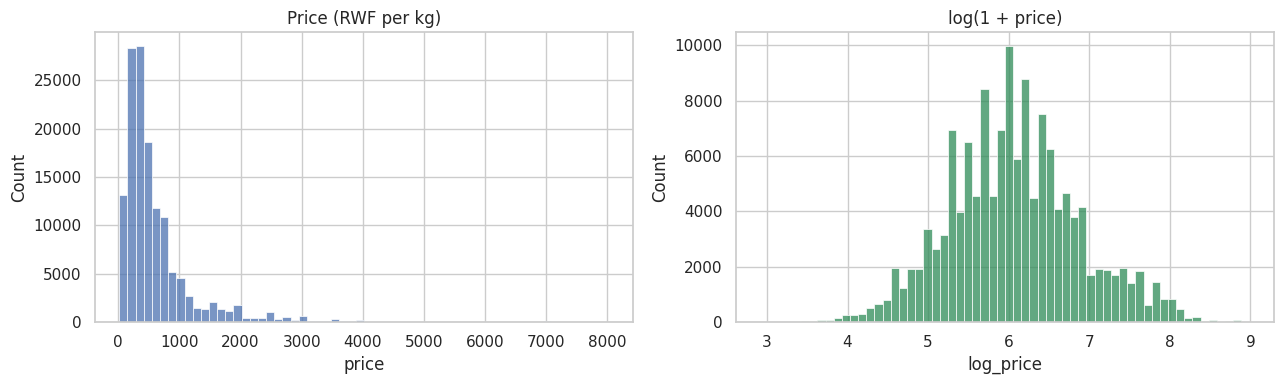

In [120]:
clean_df[LOG_TARGET] = np.log1p(clean_df[TARGET])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(clean_df[TARGET], bins=60, ax=axes[0])
axes[0].set(title="Price (RWF per kg)", xlabel="price")
sns.histplot(clean_df[LOG_TARGET], bins=60, ax=axes[1], color="seagreen")
axes[1].set(title="log(1 + price)", xlabel="log_price")
plt.tight_layout()
plt.show()

**What it shows:** The raw price is strongly right-skewed. Most foods cost under 1,000 RWF/kg, but a few (like meat and garlic) cost several thousand. After the log transform, the distribution is much closer to a bell shape.

**Decision:** We train every model on `log_price` instead of `price`. This stops a few expensive items from dominating the MSE, and it suits linear models, because price changes like inflation are multiplicative. When we make a prediction, we convert back to RWF with `expm1`. **All MSE values in this notebook are therefore on the log scale.**

### 3.2 Correlation heatmap
Correlation only works on numbers, so for this plot we also turn `category` into 0/1 columns, just to *see* how food type relates to price (it is not used as a model input).

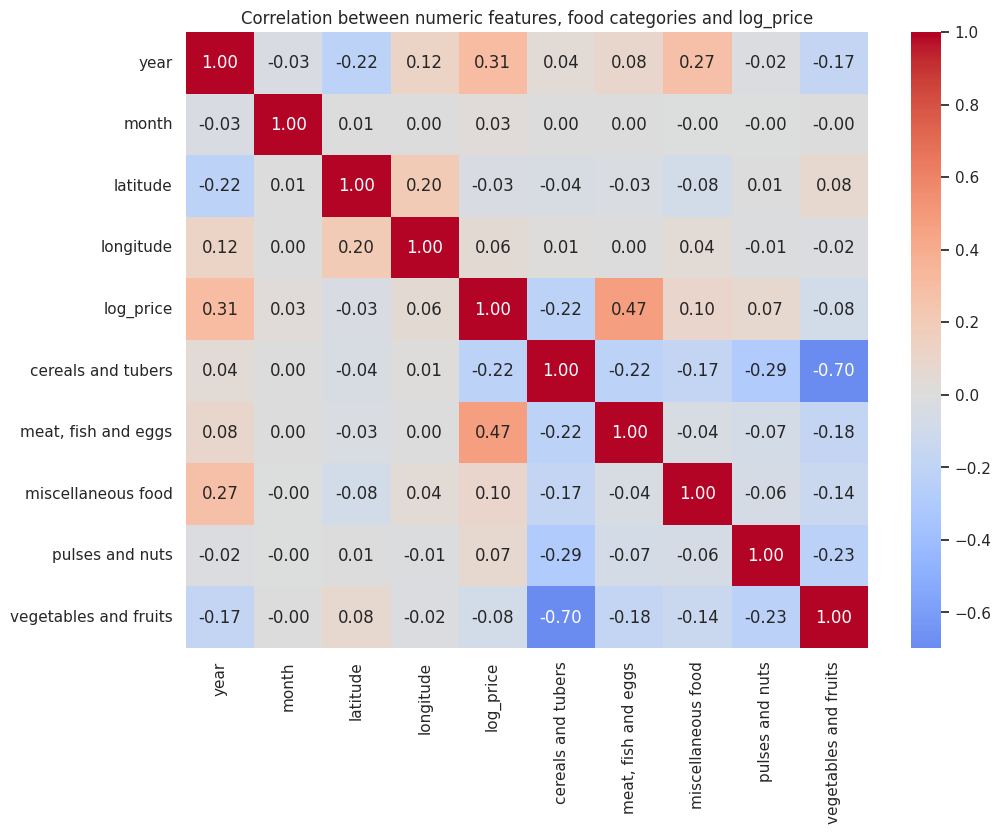

In [121]:
commodity_to_category = raw_df.drop_duplicates("commodity").set_index("commodity")["category"]
category_dummies = pd.get_dummies(clean_df["commodity"].map(commodity_to_category), dtype=int)
heatmap_df = pd.concat([clean_df[NUMERIC_FEATURES + [LOG_TARGET]], category_dummies], axis=1)

plt.figure(figsize=(11, 8))
sns.heatmap(heatmap_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features, food categories and log_price")
plt.show()

**What it shows:** `year` is the numeric feature most correlated with price (about 0.31), which is inflation at work. `month`, `latitude` and `longitude` have almost no *linear* relationship with price. The food category matters a lot: "meat, fish and eggs" is strongly positive (about 0.47) and "cereals and tubers" is negative.

**Decision:** We keep `year` and use it for the "before/after" scatter plots. We keep `commodity` (the detailed version of category) as the key categorical input. We still keep `month` and location, because their effect may be non-linear (harvest seasons, remote markets), and tree models can pick that up even when correlation is close to zero.

Because after all correlation doesn't imply causation

### 3.3 How prices change over time for the main staples

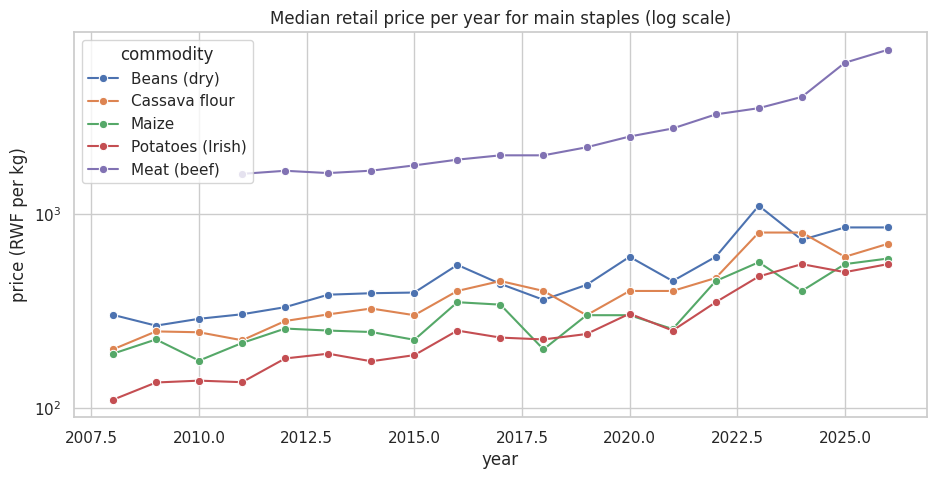

In [122]:
staples = ["Beans (dry)", "Maize", "Potatoes (Irish)", "Cassava flour", "Meat (beef)"]
yearly_median = (
    clean_df[clean_df["commodity"].isin(staples)]
    .groupby(["year", "commodity"])[TARGET].median()
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.lineplot(data=yearly_median, x="year", y=TARGET, hue="commodity", marker="o")
plt.yscale("log")  # log scale so cheap and expensive foods are both readable
plt.title("Median retail price per year for main staples (log scale)")
plt.ylabel("price (RWF per kg)")
plt.show()

**What it shows:** All staples get more expensive over time, but **not at the same speed or in the same way**. Beef rises steadily and sharply (from about 1,600 to about 7,000 RWF/kg). Maize, beans and cassava flour jump around 2022–2023 and then move in different directions (maize falls back in 2024 while cassava flour stays high).

**Decision:** Because the effect of `year` depends on *which* commodity it is, there is an **interaction** between features. A linear model can only add one fixed "year effect" for all foods, so we expect the tree-based models (Decision Tree, Random Forest) to do better.

## 4. Train/test split and preprocessing

### 4.1 Keep the newest data aside for retraining
Rows from 2026 onwards are saved to `data/new_data.csv`. This small extra file plays the role of "new data arriving" when testing the API's `/retrain` endpoint. It is separate from the test set, which is created in the next step with an 80/20 split of the remaining years. The rest of the data is saved to `data/training_data.csv`, so the API can refit the model on the original rows plus the new ones.

In [123]:
os.makedirs(DATA_DIR, exist_ok=True)

is_new = clean_df["year"] >= NEW_DATA_FROM_YEAR
model_df = clean_df[~is_new].reset_index(drop=True)
new_data_df = clean_df[is_new].reset_index(drop=True)

model_df[FEATURES + [TARGET]].to_csv(TRAINING_DATA_PATH, index=False)
new_data_df[FEATURES + [TARGET]].to_csv(NEW_DATA_PATH, index=False)

print("Rows used for modelling:", len(model_df))
print("Rows kept as new data:  ", len(new_data_df))

Rows used for modelling: 135475
Rows kept as new data:   2422


### 4.2 Split into train and test sets
We use 80% of the rows for training and 20% for testing. Every model is evaluated on this **same** test set, so the comparison is fair.

In [124]:
X = model_df[FEATURES]
y = model_df[LOG_TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (108380, 8)  Test: (27095, 8)


### 4.3 Preprocessing: scaling and encoding
`make_preprocessor` builds the steps that turn our raw columns into numbers the models can use:

- **Numeric columns** are standardised with `StandardScaler` (mean 0, standard deviation 1). Gradient descent learns much faster when features are on the same scale.
- **Categorical columns** are converted to numbers in one of two ways:
  - `"onehot"` for the **linear models**: one 0/1 column per category. A linear model can't treat "market number 37" as a quantity, so each market needs its own column.
  - `"ordinal"` for the **tree models**: each category becomes a single integer. Trees only ask "is this value ≤ x?", so they don't need one-hot columns. It also keeps them fast and small.

The preprocessor sits **inside a Pipeline**, so the scaler and encoders are fitted on the **training set only**. The test set is only transformed, never used for fitting, so no test information leaks into training.

In [125]:
def make_preprocessor(encoding):
    """Scale numeric columns and encode categorical ones ('onehot' or 'ordinal')."""
    encoders = {
        "onehot": OneHotEncoder(handle_unknown="ignore"),
        "ordinal": OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    }
    return ColumnTransformer([
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("categorical", encoders[encoding], CATEGORICAL_FEATURES),
    ])


def build_pipeline(model, encoding):
    """Preprocessing + model in one object, so it can be saved and reused as a single file."""
    return Pipeline([("preprocess", make_preprocessor(encoding)), ("model", model)])

### 4.4 One evaluation function for all models
Every model is evaluated the same way by the `evaluate` function, so the evaluation code is written only once.

**The four evaluation metrics:**

| Metric | What it means | Better when |
|---|---|---|
| **MAE** (mean absolute error) | The average size of a miss | Lower |
| **MSE** (mean squared error) | The average of the squared misses, so big misses count much more. **This is the main loss we compare.** | Lower |
| **RMSE** (root mean squared error) | The square root of MSE, back in the same unit as the price | Lower |
| **R² score** | The share of the price variation the model explains (1 = perfect, 0 = no better than always guessing the average) | Higher |

**Two scales for each metric:**
- **In log:** computed on `log_price`, the target the models are trained on (section 3.1). Here every food counts equally, because an error is roughly a *percentage* error.
- **In RWF:** the predictions are converted back to real prices (RWF per kg) before measuring. This is easier to understand, but expensive foods like meat weigh more in the result.

For each metric and scale, the table shows the **train** score and the **test** score side by side. The last row, **typical error (%)**, is explained right below each table. A large gap between train and test is a sign of overfitting.

`evaluate` also stores the scores and the fitted pipeline, so all models can be compared and the best one saved at the end (section 7).

In [126]:
METRICS = {
    "MAE": mean_absolute_error,
    "MSE": mean_squared_error,
    "RMSE": lambda y_true, y_pred: np.sqrt(mean_squared_error(y_true, y_pred)),
    "R2": r2_score,
}
METRIC_LABELS = {"MAE": "MAE", "MSE": "MSE", "RMSE": "RMSE", "R2": "R² score"}
SCALES = ["log", "RWF"]

results = []        # one row of scores per model, for the comparison table
fitted_models = {}  # model name -> fitted pipeline


def compute_metrics(y_true_log, y_pred_log):
    """Compute every metric on the log scale and in real RWF."""
    values = {
        "log": (y_true_log, y_pred_log),
        "RWF": (np.expm1(y_true_log), np.expm1(y_pred_log)),  # convert back to RWF per kg
    }
    return {(metric, scale): metric_function(*values[scale])
            for metric, metric_function in METRICS.items() for scale in SCALES}


def typical_error_percent(mse_log):
    """Turn the MSE on log prices into a typical error in %, which is easier to understand.

    Example with MSE = 0.0206:
      1. RMSE = sqrt(0.0206) = 0.1436, the typical error on the log scale.
      2. On the log scale, an error of 0.1436 means the price is off by a factor of
         e^0.1436 = 1.154, which is 15.4% too high or too low.
      3. So: typical error % = (e^RMSE - 1) * 100.
    """
    rmse_log = np.sqrt(mse_log)
    return (np.exp(rmse_log) - 1) * 100


def format_score(metric, scale, value):
    """Small log values and R² get 4 decimals, RWF errors are shown as whole francs."""
    return f"{value:.4f}" if scale == "log" or metric == "R2" else f"{value:,.0f}"


# Inline styles so the table has borders and spacing in every notebook viewer (Jupyter, VS Code, Colab)
CELL_STYLE = "border: 1px solid #cccccc; padding: 6px 14px; text-align: center;"
HEADER_STYLE = CELL_STYLE + " background: #f2f2f2; font-weight: bold;"
LABEL_STYLE = CELL_STYLE + " text-align: left; font-weight: bold;"


def show_evaluation_table(name, train_scores, test_scores, example_price=400):
    """Display the metrics as a bordered table (Train | Test in each cell) with a short note below it."""
    def cell(text, colspan=1):
        return f"<td colspan='{colspan}' style='{CELL_STYLE}'>{text}</td>"

    def train_test(train_text, test_text):
        return f"Train: {train_text} &nbsp;|&nbsp; Test: {test_text}"

    header = (f"<tr><th style='{HEADER_STYLE}'>Evaluation metric</th>"
              f"<th style='{HEADER_STYLE}'>In log</th><th style='{HEADER_STYLE}'>In RWF</th></tr>")

    rows = ""
    for metric in METRICS:
        cells = "".join(
            cell(train_test(format_score(metric, scale, train_scores[(metric, scale)]),
                            format_score(metric, scale, test_scores[(metric, scale)])))
            for scale in SCALES
        )
        rows += f"<tr><td style='{LABEL_STYLE}'>{METRIC_LABELS[metric]}</td>{cells}</tr>"

    # The typical error is a percentage, so it is the same in log and in RWF: one merged cell
    train_percent = typical_error_percent(train_scores[("MSE", "log")])
    test_percent = typical_error_percent(test_scores[("MSE", "log")])
    rows += (f"<tr><td style='{LABEL_STYLE}'>Typical error (%)</td>"
             f"{cell(train_test(f'{train_percent:.1f}%', f'{test_percent:.1f}%'), colspan=2)}</tr>")

    note = (f"<b>Typical error:</b> on the test set, predictions are usually within ±{test_percent:.1f}% "
            f"of the real price (about ±{example_price * test_percent / 100:.0f} RWF for a food costing "
            f"{example_price} RWF/kg). Lower is better.")

    display(HTML(
        f"<h4>Model evaluation: {name}</h4>"
        f"<table style='border-collapse: collapse;'>{header}{rows}</table>"
        f"<p style='margin-top: 8px;'>{note}</p>"
    ))

def evaluate(name, pipeline):
    """Score a fitted pipeline on the train and test sets, remember it, and show its evaluation table."""
    train_scores = compute_metrics(y_train, pipeline.predict(X_train))
    test_scores = compute_metrics(y_test, pipeline.predict(X_test))

    row = {"model": name}
    for (metric, scale) in train_scores:
        row[f"train_{metric}_{scale}"] = train_scores[(metric, scale)]
        row[f"test_{metric}_{scale}"] = test_scores[(metric, scale)]
    results.append(row)
    fitted_models[name] = pipeline

    show_evaluation_table(name, train_scores, test_scores)

## 5. Model 1: Linear regression with gradient descent (`SGDRegressor`)

### 5.1 Training loop with `partial_fit`
`SGDRegressor.fit()` does not save the loss after each epoch, so we train it ourselves:
1. Each epoch, we shuffle the training rows (gradient descent works better with shuffled data).
2. We call `partial_fit`, which makes **one pass** over the data.
3. After the pass, we record the train MSE and test MSE.

The preprocessor is fitted **once** on the training set and reused for every run, so the tuning loop doesn't redo the same work.

In [127]:
sgd_preprocessor = make_preprocessor("onehot").fit(X_train)
X_train_encoded = sgd_preprocessor.transform(X_train)
X_test_encoded = sgd_preprocessor.transform(X_test)


def train_sgd(learning_rate, alpha, epochs):
    """Train an SGDRegressor epoch by epoch and record train/test MSE after each epoch."""
    model = SGDRegressor(learning_rate="constant", eta0=learning_rate,
                         alpha=alpha, random_state=RANDOM_STATE)
    rng = np.random.default_rng(RANDOM_STATE)
    history = {"train_mse": [], "test_mse": []}

    for _ in range(epochs):
        order = rng.permutation(X_train_encoded.shape[0])
        model.partial_fit(X_train_encoded[order], y_train.values[order])
        history["train_mse"].append(mean_squared_error(y_train, model.predict(X_train_encoded)))
        history["test_mse"].append(mean_squared_error(y_test, model.predict(X_test_encoded)))

    return model, history

### 5.2 Hyperparameter tuning
We try every combination of:
- **Learning rate** (`eta0`): how big each gradient descent step is.
- **Regularisation strength** (`alpha`): how strongly large weights are penalised (L2), to reduce overfitting.
- **Number of epochs**: how many passes over the training data.

**Trick to save time:** each run trains for 50 epochs, and the loss after 10 or 25 epochs is already in the history. Reading it from there gives the same result as training separately for 10 or 25 epochs, because the random seed is fixed.

*Note: we pick the settings using the test set so that all four models are judged on one shared test set. In a larger project you would tune on a separate validation set.*

In [128]:
LEARNING_RATES = [0.001, 0.01, 0.1]
ALPHAS = [0.0001, 0.001, 0.01]
EPOCH_CHECKPOINTS = [10, 25, 50]

tuning_rows = []
for learning_rate in LEARNING_RATES:
    for alpha in ALPHAS:
        _, history = train_sgd(learning_rate, alpha, epochs=max(EPOCH_CHECKPOINTS))
        for epochs in EPOCH_CHECKPOINTS:
            tuning_rows.append({
                "learning_rate": learning_rate,
                "alpha": alpha,
                "epochs": epochs,
                "test_mse": history["test_mse"][epochs - 1],
            })

tuning_df = pd.DataFrame(tuning_rows)
tuning_df.pivot_table(index=["learning_rate", "alpha"], columns="epochs", values="test_mse").round(4)

epochs                    10      25      50
learning_rate alpha                         
0.001         0.0001  0.0834  0.0830  0.0829
              0.0010  0.0867  0.0865  0.0863
              0.0100  0.1816  0.1615  0.1505
0.010         0.0001  0.0846  0.0882  0.0870
              0.0010  0.0873  0.0902  0.0895
              0.0100  0.1485  0.1521  0.1555
0.100         0.0001  0.1240  0.1272  0.1447
              0.0010  0.1258  0.1331  0.1509
              0.0100  0.1970  0.2504  0.2717

In [129]:
best_sgd_params = tuning_df.loc[tuning_df["test_mse"].idxmin()]
print("Best SGD settings:")
print(best_sgd_params)

Best SGD settings:
learning_rate     0.001000
alpha             0.000100
epochs           50.000000
test_mse          0.082947
Name: 2, dtype: float64


**What tuning showed:**
- **Learning rate:** 0.001 gives the lowest and most stable loss. With 0.1 the steps are too big: the loss is unstable and even gets *worse* with more epochs, because the model keeps overshooting the minimum.
- **Alpha (regularisation):** the smallest value (0.0001) works best. Raising it to 0.01 almost doubles the test MSE, because the model is *underfitting*. With about 100,000 rows we have enough data, so strong regularisation is not needed.
- **Epochs:** with a small learning rate, the loss is almost flat after 10 epochs, so more epochs only give a tiny improvement.

### 5.3 Train the final SGD model and plot the loss curve
We retrain with the best settings and plot the train and test MSE for each epoch on one chart.

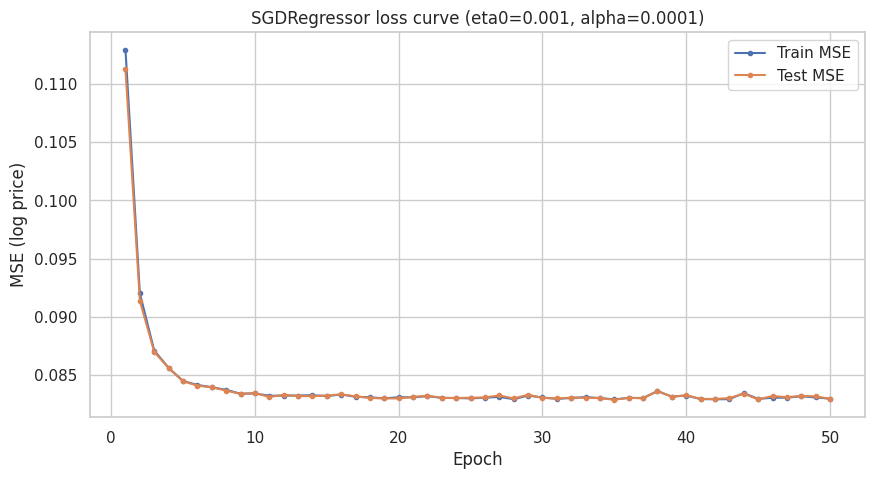

In [130]:
best_learning_rate = best_sgd_params["learning_rate"]
best_alpha = best_sgd_params["alpha"]
best_epochs = int(best_sgd_params["epochs"])

sgd_model, sgd_history = train_sgd(best_learning_rate, best_alpha, best_epochs)

epoch_numbers = range(1, best_epochs + 1)
plt.figure(figsize=(10, 5))
plt.plot(epoch_numbers, sgd_history["train_mse"], label="Train MSE",marker="o", markersize=3)
plt.plot(epoch_numbers, sgd_history["test_mse"], label="Test MSE", marker="o", markersize=3)
plt.title(f"SGDRegressor loss curve (eta0={best_learning_rate}, alpha={best_alpha})")
plt.xlabel("Epoch")
plt.ylabel("MSE (log price)")
plt.legend()
plt.show()

**What it shows:** Both curves drop quickly in the first few epochs and then flatten, which means gradient descent has converged. Train and test MSE stay very close together, so the model is **not overfitting**. Its error comes from a straight line not being able to capture the commodity-by-year interactions seen in section 3.3, not from overfitting.

In [131]:
# Wrap the already-fitted preprocessor and model in a Pipeline so it is evaluated like the others
sgd_pipeline = Pipeline([("preprocess", sgd_preprocessor), ("model", sgd_model)])
evaluate("SGDRegressor (gradient descent)", sgd_pipeline)

## 6. The other three models
Thanks to `build_pipeline` and `evaluate`, each model needs only a few lines: choose the model, choose the encoding, fit, then evaluate. Each one ends with the same evaluation table as the SGD model.

### 6.1 Model 2: Linear regression, closed form (`LinearRegression`)
This solves the least-squares equation directly, with no learning rate or epochs. It should land very close to SGD, which is a good check that our gradient descent worked.

In [132]:
linear_pipeline = build_pipeline(LinearRegression(), "onehot").fit(X_train, y_train)
evaluate("LinearRegression (closed form)", linear_pipeline)

### 6.2 Model 3: Decision tree (`DecisionTreeRegressor`)
`min_samples_leaf=3` stops the tree from creating leaves for single rows, which limits overfitting.

In [133]:
tree_pipeline = build_pipeline(
    DecisionTreeRegressor(min_samples_leaf=3, random_state=RANDOM_STATE), "ordinal"
).fit(X_train, y_train)
evaluate("DecisionTreeRegressor", tree_pipeline)

### 6.3 Model 4: Random forest (`RandomForestRegressor`)
A random forest averages many trees, each trained on a random sample of rows and features, which reduces the variance of a single tree.
- `n_estimators=50`: enough trees for a stable average while keeping the saved file small enough for Render's free plan (512 MB RAM).
- `max_features=0.8`: each split looks at 80% of the features, which makes the trees more different from each other.
- `min_samples_leaf=3`: same overfitting control as the single tree.

In [134]:
forest_pipeline = build_pipeline(
    RandomForestRegressor(n_estimators=50, max_features=0.8, min_samples_leaf=3,
                          n_jobs=-1, random_state=RANDOM_STATE),
    "ordinal",
).fit(X_train, y_train)
evaluate("RandomForestRegressor", forest_pipeline)

### 6.4 Which features matter most?
With ordinal encoding, each of our 8 features is exactly one column, so the random forest importances can be read directly.

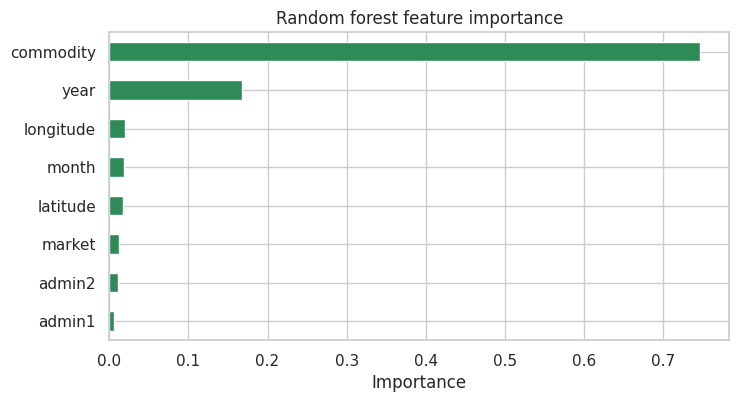

In [135]:
importances = pd.Series(
    forest_pipeline.named_steps["model"].feature_importances_, index=FEATURES
).sort_values()

importances.plot(kind="barh", figsize=(8, 4), color="seagreen")
plt.title("Random forest feature importance")
plt.xlabel("Importance")
plt.show()

**What it shows:** `commodity` is by far the most important feature (what you are buying decides most of the price), followed by `year` (inflation). Location and month add smaller adjustments. This confirms what we saw in the heatmap and the line plot.

## 7. Comparing the four models
The table below collects the main scores of every model in one place:
- `train_MSE_log` and `test_MSE_log`: MSE on log price. **This is the score used to choose the best model.**
- `train_MSE_RWF` and `test_MSE_RWF`: the same MSE in real prices (RWF per kg, squared).
- `test_R2_log`: the share of price variation explained on the test set (closer to 1 is better).
- `test_MAE_RWF`: the average size of a miss on the test set, in RWF per kg.
- `typical_error_%`: the test MSE (log) turned into a percentage. With log prices, a root mean squared error of `r` means predictions are typically off by about `e^r − 1`.

The models are sorted from best to worst test MSE (log). The RWF columns give the same ranking, so the choice of the best model doesn't depend on the scale.

In [136]:
COMPARISON_COLUMNS = ["train_MSE_log", "test_MSE_log", "train_MSE_RWF", "test_MSE_RWF",
                      "test_R2_log", "test_MAE_RWF", "typical_error_%"]

comparison = pd.DataFrame(results).set_index("model").sort_values("test_MSE_log")
comparison["typical_error_%"] = typical_error_percent(comparison["test_MSE_log"])
comparison[COMPARISON_COLUMNS].round({
    "train_MSE_log": 4, "test_MSE_log": 4, "train_MSE_RWF": 0, "test_MSE_RWF": 0,
    "test_R2_log": 4, "test_MAE_RWF": 0, "typical_error_%": 1,
})

,train_MSE_log,test_MSE_log,train_MSE_RWF,test_MSE_RWF,test_R2_log,test_MAE_RWF,typical_error_%
model,,,,,,,
RandomForestRegressor,0.0107,0.0207,5798.0,11768.0,0.9681,48.0,15.5
DecisionTreeRegressor,0.0091,0.0265,4865.0,15041.0,0.9591,53.0,17.7
LinearRegression (closed form),0.0827,0.0828,43465.0,45789.0,0.8722,113.0,33.3
SGDRegressor (gradient descent),0.0830,0.0829,43852.0,46009.0,0.8719,113.0,33.4


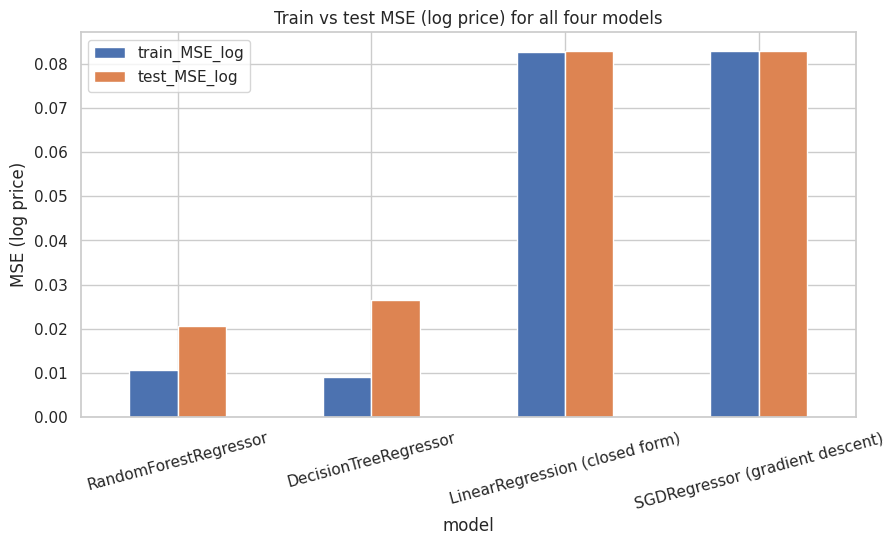

Best model (lowest test MSE): RandomForestRegressor


In [137]:
comparison[["train_MSE_log", "test_MSE_log"]].plot(kind="bar", figsize=(10, 5), rot=15)
plt.title("Train vs test MSE (log price) for all four models")
plt.ylabel("MSE (log price)")
plt.show()

best_model_name = comparison["test_MSE_log"].idxmin()
best_pipeline = fitted_models[best_model_name]
print(f"Best model (lowest test MSE): {best_model_name}")

### Choosing the best model
**Rule:** the best model is the one with the **lowest test MSE**, because the test set is data the model never saw during training. That is the closest thing we have to real future requests.

**The Random Forest has the lowest test MSE, so it is our best model.** Here is how the dataset affected each model:
- **SGDRegressor and LinearRegression** score almost the same (test MSE about 0.083, test R² about 0.87, roughly 33% typical error, an average miss of about 113 RWF/kg). That makes sense, since they are two ways of solving the same linear problem. They can only add up fixed effects ("beef adds X", "each year adds Y") and can't model the fact that inflation and seasons hit each commodity differently.
- **DecisionTreeRegressor** cuts the error by about 3×, because it can split by commodity first and then by year and market, which captures those interactions. Its evaluation table shows a clear gap between train and test (MSE 0.0091 vs 0.0266, average miss 31 vs 53 RWF/kg), which is a sign of some overfitting.
- **RandomForestRegressor** averages 50 trees, which lowers that overfitting. It gets the lowest test MSE (0.0206, about 15% typical error) and the highest test R² (about 0.97, so it explains about 97% of the price variation), with an RMSE of about 108 RWF/kg and an average miss (MAE) of about 48 RWF/kg.

**Is this error high or low?** For this use case, a typical error of about 15% (on average under 50 RWF per kg) is reasonably low. Food prices in local markets change a lot from month to month and from one market to another. An estimate within roughly 15% is close enough to help a farmer compare markets and months before selling. To reduce the error further, we could add features like rainfall or harvest season data, use more recent data, or try boosting models.

## 8. Scatter plots: before and after fitting a regression line
Linear regression finds the **straight line that best fits the data**: the line with the smallest total squared distance to all the points. Our real models use 8 features, which can't be drawn on a flat chart. So here we use **one feature on the x-axis and the price on the y-axis** to *see* that line, and to see why one straight line is not enough for this data.

- **x-axis: `year`**, the numeric feature most correlated with the price (0.31 in the heatmap, section 3.2).
- **y-axis: `log_price`**, the same target our models learn (section 3.1). The labels show real prices in RWF per kg (50, 100, 250, …) on a log scale, so they are easy to read.
- **The line comes from a separate, very simple model that uses `year` only.** It exists only for these plots. Our real models (sections 5–6) use all 8 features.

The function below draws the scatter plot, and adds the fitted line only when we give it a model, so the "before" and "after" plots use the same code.

In [138]:
TOP_FEATURE = "year"
PLOT_SAMPLE_SIZE = 5000
PRICE_TICKS_RWF = [50, 100, 250, 500, 1000, 2500, 5000]  # y-axis labels in real prices

train_df = X_train.assign(**{LOG_TARGET: y_train})
train_df["category"] = train_df["commodity"].map(commodity_to_category)  # only used for dot colours
sample = train_df.sample(PLOT_SAMPLE_SIZE, random_state=RANDOM_STATE)


def plot_feature_vs_target(line_model=None):
    """Scatter TOP_FEATURE against log price (coloured by food category),
    and draw the regression line if a model is given."""
    plt.figure(figsize=(11, 6))
    jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.3, 0.3, len(sample))
    sns.scatterplot(x=sample[TOP_FEATURE] + jitter, y=sample[LOG_TARGET], hue=sample["category"],
                    palette="tab10", alpha=0.6, s=14, linewidth=0)
    title = "Price vs year (before fitting a line)"

    if line_model is not None:
        x_line = np.linspace(sample[TOP_FEATURE].min(), sample[TOP_FEATURE].max(), 100)
        y_line = line_model.predict(pd.DataFrame({TOP_FEATURE: x_line}))
        plt.plot(x_line, y_line, color="red", linewidth=3, label="fitted regression line")
        title = "Price vs year with the fitted regression line"

    years = range(sample[TOP_FEATURE].min(), sample[TOP_FEATURE].max() + 1, 2)
    plt.xticks(years)  # whole years only (no 2012.5)
    plt.yticks(np.log1p(PRICE_TICKS_RWF), [f"{price:,}" for price in PRICE_TICKS_RWF])
    plt.title(title)
    plt.xlabel("year")
    plt.ylabel("price in RWF per kg (log scale)")
    plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="food category", markerscale=2)
    plt.tight_layout()
    plt.show()

### 8.1 Before fitting a line
**How to read this plot:**
- **Each dot is one price record: one commodity, in one market, in one month.** For example, *"Maize in Byumba market, March 2014, 250 RWF/kg"*. The column above a year holds many such records mixed together: different foods, markets and months.
- **Only a random sample of 5,000 records is drawn**, out of more than 100,000 training records. Drawing all of them would turn the chart into one solid block.
- **The x-axis shows the year only**, not the month. Each dot is moved slightly left or right at random (by less than half a year) so the dots don't pile up on one thin vertical line. This is called **jitter**. The position of a dot inside its column has no meaning, and it doesn't change the data.
- **The colour is the food category** of the record. Category is not a model input. It is only used here to show where the spread of prices comes from.

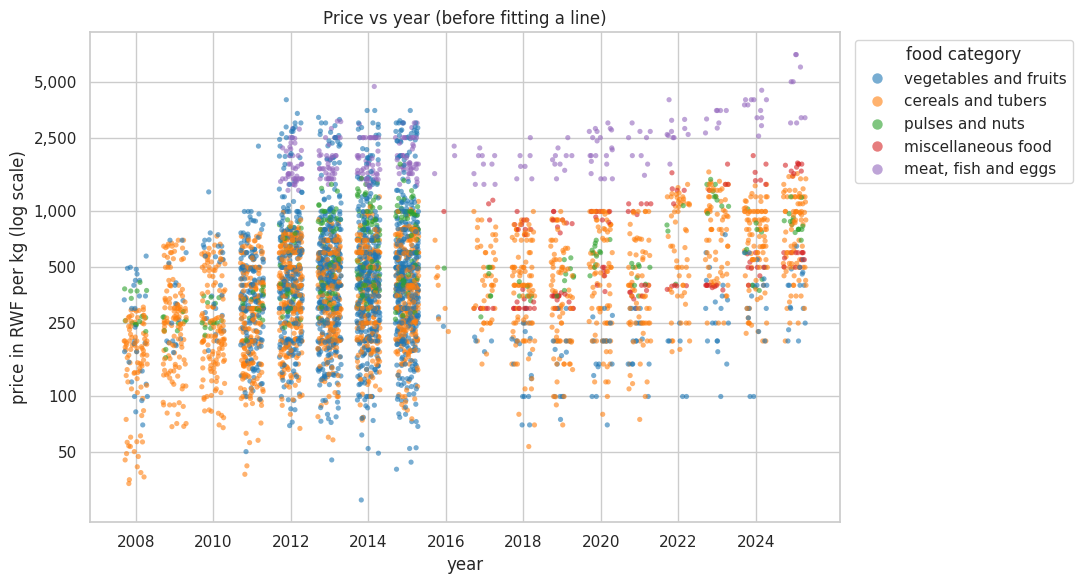

In [139]:
plot_feature_vs_target()

**What it shows:**
- **There is an upward trend.** Dots in recent years sit higher than dots in 2008–2010, because food has become more expensive over time (inflation).
- **Each year has a huge vertical spread**, from about 50 to over 5,000 RWF/kg, and the colours show it comes from the **different foods**. "Meat, fish and eggs" (purple) is near the top in every year it was recorded (from 2011), while the cheapest records (vegetables, cassava, sweet potatoes) are near the bottom. Within one year, *what* is sold matters much more than *when*.
- **Some years have far more dots than others**, especially 2011–2015. WFP recorded more foods and markets in those years. The number of dots reflects how much data was collected, not the prices.

### 8.2 After fitting a line
We train the simple linear regression that uses **`year` only** on the training set, print what its line means in real prices, and draw it on top of the same dots.

The line goes up by about 5.9% per year.
Line value in 2008: about 289 RWF/kg
Line value in 2025: about 767 RWF/kg

In 2014, the line predicts about 408 RWF/kg for every food.
Real median price of Cabbage in 2014: about 97 RWF/kg
Real median price of Meat (beef) in 2014: about 1,667 RWF/kg


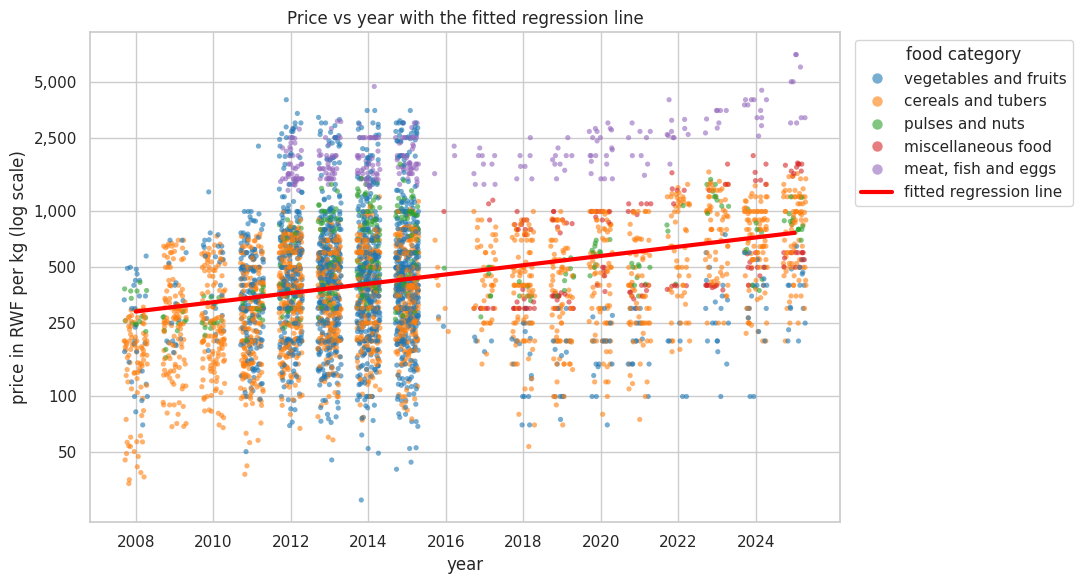

In [140]:
one_feature_model = LinearRegression().fit(train_df[[TOP_FEATURE]], train_df[LOG_TARGET])

yearly_increase = np.exp(one_feature_model.coef_[0]) - 1
first_year, last_year = train_df[TOP_FEATURE].min(), train_df[TOP_FEATURE].max()
line_start, line_end = np.expm1(one_feature_model.predict(
    pd.DataFrame({TOP_FEATURE: [first_year, last_year]})))

print(f"The line goes up by about {yearly_increase:.1%} per year.")
print(f"Line value in {first_year}: about {line_start:,.0f} RWF/kg")
print(f"Line value in {last_year}: about {line_end:,.0f} RWF/kg")

# Compare the line with real prices for a cheap and an expensive food in one year
EXAMPLE_YEAR = 2014
line_value = np.expm1(one_feature_model.predict(pd.DataFrame({TOP_FEATURE: [EXAMPLE_YEAR]})))[0]
print(f"\nIn {EXAMPLE_YEAR}, the line predicts about {line_value:,.0f} RWF/kg for every food.")
year_prices = train_df[train_df[TOP_FEATURE] == EXAMPLE_YEAR]
for food in ["Cabbage", "Meat (beef)"]:
    real_price = np.expm1(year_prices.loc[year_prices["commodity"] == food, LOG_TARGET]).median()
    print(f"Real median price of {food} in {EXAMPLE_YEAR}: about {real_price:,.0f} RWF/kg")

plot_feature_vs_target(one_feature_model)

**What it shows:**
- **The red line is the best straight line through all the training records.** Out of all possible straight lines, it has the smallest total squared distance to the dots.
- **The line rises about 6% per year**, from about 290 RWF/kg in 2008 to about 770 RWF/kg in 2025. This is roughly the average yearly increase in food prices in these markets. On a log scale, a constant *percentage* increase shows up as a straight line.
- **The line gives only one price per year, the same for every food.** This simple model has only one input, the year. It doesn't know which food a record is about, so for each year it returns one single price for all foods. For example, in 2014 it predicts about 410 RWF/kg for cabbage, for beef, and for every other food. In reality, cabbage cost about 100 RWF/kg and beef about 1,700 RWF/kg that year (printed above the plot). So the line is far **too high** for cheap foods (the vegetable dots at the bottom) and far **too low** for expensive foods (the meat dots at the top). The vertical distance between a dot and the line is the model's error for that record, and for most dots it is large.

**What we learn:** `year` explains the overall trend, but the food itself explains most of the price. This is why the full models also use `commodity` and location, and why the tree models do much better: they can combine features (for example, "beef *and* 2023") instead of adding up one fixed effect per feature (section 7).

## 9. Save the best model and predict

### 9.1 Save the model with its preprocessing
We save the whole Pipeline (scaler + encoder + model) with `joblib`. This way the API only needs to send raw values such as `"Maize"` or `"Kigali City"`. The pipeline handles all the preprocessing. `compress=3` makes the file smaller so it fits easily in a GitHub repository.

In [141]:
joblib.dump(best_pipeline, MODEL_PATH, compress=3)
print(f"Saved '{best_model_name}' to {MODEL_PATH} "
      f"({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

Saved 'RandomForestRegressor' to best_model.joblib (40.1 MB)


### 9.2 Prediction function (reused by the API)
`predict_price` takes **one row as a dictionary**, which is the same shape as the JSON body the API will receive. It loads the saved model, predicts the log price and converts it back to RWF.

In [142]:
def predict_price(input_row, model_path=MODEL_PATH):
    """Predict the retail price (RWF per kg) for one row given as a dict of the 8 features."""
    model = joblib.load(model_path)
    row = pd.DataFrame([input_row])[FEATURES]
    log_prediction = model.predict(row)[0]
    return float(np.expm1(log_prediction))

### 9.3 Predict one row of the test set
We take the first row of the test set, predict its price and compare it with the real price.

In [143]:
test_row = X_test.iloc[0].to_dict()
actual_price = float(np.expm1(y_test.iloc[0]))
predicted_price = predict_price(test_row)

print("Input:")
for feature, value in test_row.items():
    print(f"  {feature:<10}: {value}")
print(f"\nPredicted price: {predicted_price:,.0f} RWF/kg")
print(f"Actual price:    {actual_price:,.0f} RWF/kg")
print(f"Difference:      {abs(predicted_price - actual_price) / actual_price * 100:.1f}%")

Input:
  year      : 2020
  month     : 3
  latitude  : -2.67
  longitude : 29.85
  admin1    : Southern Province
  admin2    : Gisagara
  market    : Mugombwa (Camp)
  commodity : Cabbage

Predicted price: 174 RWF/kg
Actual price:    175 RWF/kg
Difference:      0.4%


## 10. Summary
- **Dataset:** WFP Rwanda retail food prices, about 138k rows after cleaning, with 8 features (4 numeric and 4 categorical).
- **Target:** price in RWF/kg, learned on a log scale because the prices are skewed.
- **Models:** SGDRegressor (tuned, with loss curve), LinearRegression, DecisionTree and RandomForest, all evaluated on the same test set with MSE.
- **Best model:** RandomForestRegressor (lowest test MSE), saved with its preprocessing to `best_model.joblib`.
- **Files used by the API:**
  - `best_model.joblib`: the model to serve
  - `data/training_data.csv`: the original data, used when `/retrain` refits the model
  - `data/new_data.csv`: 2026 rows to upload when demoing `/retrain`
  - `predict_price()`: the prediction logic the API will reuse

# Further analysis: new data and retraining
Sections 1–10 evaluate the models with a random 80/20 split. This is the standard way to compare models, but it makes the error look smaller than it will be in real use. The test rows come from the same years, months and markets as the training rows (2008-2025), so the model is never asked to predict a period it hasn't seen like 2026. Once deployed, the model is expected to predict future prices, and prices keep changing because of inflation and harvests.

The 2026 rows in `data/new_data.csv` were kept out of training (section 4.1), so they are genuinely new data for the model. This section uses them to answer three questions, and the answers decide how the API's `/retrain` endpoint works:
1. How well does our saved model do on future prices, compared with the random test set (from 2008-2025)?
2. Does retraining with recent prices make predictions better?
3. Which data should `/retrain` use to check that a retrained model is good before using it?

## A. Accuracy on new data, and the effect of retraining
In the table below, each check works like an exam: a model gets the 8 inputs of each row (year, month, latitude, longitude, province, district, market, commodity), the real price is hidden, the model predicts a price, and the prediction is compared with the real price.

- **Random test set 2008-2025:** the saved model (from section 9) learned from 80% of the 2008–2025 rows and predicts the other 20%. This is the same result we got earlier, so we used this as a baseline.
- **All 2026 prices:** the same saved model predicts every price in `data/new_data.csv` (January–August 2026). We give it a test from any of the 2026 data (like march 2026), then it predicts. Note that it has never seen any 2026 price.
- **Latest month, before retraining:** the same saved model predicts only the newest month in the 2026 data, i.e August 2026 which 117 prices. It only learned 2008–2025, so it has to guess August 2026 prices from what prices looked like up to 2025.
- **Latest month, after retraining:** a copy of the model learns from 2008–2025 **plus** January–July 2026, as `/retrain` would do, and then predicts the same 117 August 2026 prices.

**Why compare the last two columns?** They answer one question: *does retraining help?* Both columns predict **the same 117 August prices**. The only difference is what the model learned beforehand:

| | Learned from | Predicts |
|---|---|---|
| Before retraining | 2008–2025 | August 2026 (117 prices) |
| After retraining | 2008–2025 **+ January–July 2026** | the same August 2026 (117 prices) |

Since the prices being predicted are identical, the comparison is fair. If the error is smaller after retraining, it can only be because the model learned the recent months.

The measures are the **MSE on log prices** (the loss used in sections 5–7) and the **typical error** derived from it (`e^RMSE − 1`), with the average miss in RWF per kg shown underneath. The last row shows how often the prediction was **below the real price**. Around 50% means the model guesses too low as often as too high, so it is balanced. Above 50% means it keeps guessing too low.

In [144]:
from sklearn.base import clone

# Rows the saved model trained on and was tested on (sections 4.2 and 7), with prices in RWF
train_rows = X_train.assign(**{TARGET: np.expm1(y_train)})
test_rows = X_test.assign(**{TARGET: np.expm1(y_test)})

# The latest month in the new data (year * 100 + month, e.g. 202608 = August 2026)
new_data_period = new_data_df["year"] * 100 + new_data_df["month"]
latest_period = new_data_period.max()
latest_rows = new_data_df[new_data_period == latest_period]
earlier_rows = new_data_df[new_data_period < latest_period]


def log_mse(model, rows):
    """MSE on log prices, the same loss used in the rest of the notebook."""
    return mean_squared_error(np.log1p(rows[TARGET]), model.predict(rows[FEATURES]))


def train_candidate(extra_rows):
    """Retrain the best model's pipeline on the original training rows plus extra rows (what /retrain does)."""
    rows = pd.concat([train_rows, extra_rows])
    return clone(best_pipeline).fit(rows[FEATURES], np.log1p(rows[TARGET]))


def describe_errors(model, rows):
    """Measure how far off a model is on rows it has never seen. Each key becomes one row of the table."""
    actual = rows[TARGET].to_numpy()
    predicted = np.expm1(model.predict(rows[FEATURES]))
    typical_error = typical_error_percent(log_mse(model, rows))
    average_miss = mean_absolute_error(actual, predicted)
    return {
        "Prices checked": f"{len(rows):,}",
        "MSE on log prices": f"{log_mse(model, rows):.4f}",
        "Typical error (average miss in RWF/kg)": f"{typical_error:.1f}%\n(~{average_miss:.0f} RWF/kg)",
        "Predictions below the real price (50% = balanced)": f"{np.mean(actual > predicted) * 100:.0f}%",
    }


retrained_pipeline = train_candidate(earlier_rows)

# One column per check, one row per measure
accuracy_checks = pd.DataFrame({
    "Random test set\n(2008-2025)": describe_errors(best_pipeline, test_rows),
    "All 2026 prices\n(Jan-Aug 2026)": describe_errors(best_pipeline, new_data_df),
    "Latest month\n(before retraining)": describe_errors(best_pipeline, latest_rows),
    "Latest month\n(after retraining)": describe_errors(retrained_pipeline, latest_rows),
})

print(f"Latest month in the new data: {latest_period % 100}/{latest_period // 100}")
# pre-wrap shows each "\n" (in the cells and in the column names) as a line break
accuracy_checks.style.set_properties(**{"white-space": "pre-wrap", "text-align": "center"}).set_table_styles([
    {"selector": "th.col_heading", "props": [("white-space", "pre-wrap"), ("text-align", "center")]},
])

Latest month in the new data: 8/2026


,Random test set (2008-2025),All 2026 prices (Jan-Aug 2026),Latest month (before retraining),Latest month (after retraining)
Prices checked,"27,095","2,422",117,117
MSE on log prices,0.0207,0.0385,0.0175,0.0048
Typical error (average miss in RWF/kg),15.5% (~48 RWF/kg),21.7% (~176 RWF/kg),14.2% (~90 RWF/kg),7.2% (~47 RWF/kg)
Predictions below the real price (50% = balanced),50%,74%,68%,51%


**What it shows:**
- **The random test set overstates how well the model will do in real use.** On prices it has never seen, the error is ~1.5 times larger. More importantly, the errors are not random: the model mostly predicts **below** the real price. For a farmer, that means being told a price that is too low, which could lead to selling a harvest too cheaply.
- **The cause is the model, not the data.** A Random Forest answers with the average price of similar rows it has already seen, so it can never predict a price higher than the levels it learned. For 2026, it falls back on 2025 prices and misses the inflation since then. The random test set hides this, because its test rows come from the same years as the training rows, so the model never has to look beyond what it knows.
- **Retraining on recent months fixes both problems.** After learning January–July 2026, the model predicts August with a smaller error than even the random test set, and it is no longer biased downwards. The most recent prices carry the most information about next month's prices.
- **What this means for how the model is used:** its accuracy depends less on which algorithm was chosen (section 7) and more on how recent its training data is. It works best as a short-term tool, retrained every month as new prices arrive, which is the purpose of the `/retrain` endpoint. The August check has only 117 prices, so this is a strong sign rather than a final result.

## B. Checking a retrained model before using it
**The problem.** The API has a model running (the **current model**), which learned prices up to 2025. When new prices are uploaded to `/retrain`, the API should learn from them, but it can't blindly trust the file. It might contain mistakes: prices typed with extra zeros, prices per sack instead of per kg, or columns in the wrong order. If the API retrained on such a file and switched straight away, every price shown to users would be wrong, and nobody would notice, because the API would keep answering requests. So before switching, the new model has to be **tested**.

**How the test works.** With an upload of January–August 2026 prices:
1. **Hide the newest month.** The August 2026 prices are set aside. No model trains on them.
2. **Train a new model** on the original data plus January–July 2026.
3. **There are now two models:** the current model, which knows prices up to 2025, and the new model, which knows prices up to July 2026.
4. **Give both the same exam.** Both models predict the hidden August prices. The real August prices are known, so each model's MSE (log) can be measured.
5. **Decide.** If the new model's MSE is less than or equal to the current model's, the API switches to it, then retrains once more including August so no data is wasted. If it is higher, the current model stays and the upload is reported as suspicious. "Equal" is allowed so that good data is still learned even when it doesn't immediately lower the error.

**Why the newest month is used as the exam.** A useful exam has to be:
- **Fair:** neither model has seen the answers. A model tested on prices it trained on looks better than it is. August is hidden from both models, so the test is fair.
- **About the future:** the model will predict the coming months, so the exam should use the most recent prices. How well a model predicts maize prices in 2012 says little about what the prices will be in December 2026.

The obvious alternative is the old random test set (from the earlier 80/20 split). It is fair, since neither model trained on it, but it only contains 2008–2025 prices, so it tests the past rather than the future. It is included in the cell below only for comparison: the API itself uses the newest month.

**How the comparison works.** A good exam must accept good data and reject bad data. The model is retrained with three simulated uploads of January–July 2026, and each new model takes both exams:
- **Good data:** the real prices. It should be accepted.
- **Shuffled prices:** the prices are randomly moved to other rows, breaking the link between the inputs and the price, as when columns are mixed up. It should be rejected.
- **Prices 100× too big:** a unit or typing error. It should be rejected.

In [145]:
rng = np.random.default_rng(RANDOM_STATE)
uploads = {
    "good data (real earlier 2026 prices)": earlier_rows,
    "bad data (prices shuffled between rows)": earlier_rows.assign(
        **{TARGET: rng.permutation(earlier_rows[TARGET].to_numpy())}),
    "bad data (prices typed 100x too big)": earlier_rows.assign(**{TARGET: earlier_rows[TARGET] * 100}),
}

current_check_mse = log_mse(best_pipeline, latest_rows)
quality_checks = [{
    "model": "Current model (no retraining)",
    "MSE_on_old_test_set": log_mse(best_pipeline, test_rows),
    "MSE_on_latest_month": current_check_mse,
    "decision": "-",
}]
for upload_name, upload_rows in uploads.items():
    # The good upload is exactly what retrained_pipeline was trained on, so reuse it
    candidate = retrained_pipeline if upload_rows is earlier_rows else train_candidate(upload_rows)
    candidate_check_mse = log_mse(candidate, latest_rows)
    quality_checks.append({
        "model": f"Retrained with {upload_name}",
        "MSE_on_old_test_set": log_mse(candidate, test_rows),
        "MSE_on_latest_month": candidate_check_mse,
        "decision": "accept" if candidate_check_mse <= current_check_mse else "reject",
    })

pd.DataFrame(quality_checks).set_index("model").round(4)

,MSE_on_old_test_set,MSE_on_latest_month,decision
model,,,
Current model (no retraining),0.0207,0.0175,-
Retrained with good data (real earlier 2026 prices),0.0206,0.0048,accept
Retrained with bad data (prices shuffled between rows),0.0206,0.1513,reject
Retrained with bad data (prices typed 100x too big),0.0205,21.2526,reject


**What it shows:**
-  **The old random test set can't tell good data from bad.** Random-test questions are about older years, such as "maize in Huye in 2012" or "beans in Musanze in 2018". The Random Forest answers each one by sorting the row into a group of similar rows (same food, similar years, similar market) and giving that group's average price. The uploaded 2026 prices only go into the groups for the most recent years (2026, and sometimes 2024–2025), so the groups for older years are untouched. That is why all three retrained models give the same answers for older years, whether they learned from good or bad data, and why testing on old prices, like September 2022, always returns the same MSE. To see the difference, we need to test on 2026 prices, where the change actually happens.
- - **Before retraining, the August 2026 prices are held back**. Then every model is asked "what did maize cost in Huye in August 2026?" and compared with the real price. These questions fall into the recent-year groups, exactly where the uploaded prices went, so the quality of the upload shows directly:
  - The model retrained on **real prices** knows recent price levels and answers closer than the current model (MSE about 0.005 against 0.017), so it is **accepted**.
  - The model retrained on **prices 100× too big** answers around 55,000 RWF/kg instead of about 550 (MSE about 21), and the one trained on **shuffled prices** gives prices that belong to other foods and markets (MSE about 0.15). Both are **rejected**, and the current model keeps serving predictions.

**What this means for the API:**
1. `/retrain` keeps the latest month of the upload aside, trains a new model on the original data plus the earlier months, and only uses it if its MSE (log) on that month is at most the current model's. Once accepted, it retrains on all rows, including the latest month, so no new data is wasted. The previous model is kept as a backup.
2. The further a prediction is from the last month the model learned, the more the error grows. So retraining regularly is the most effective way to keep it low, more than further retraining on the random split.